# Social Cluster Recommendation Engine for Co-Mutating Genes — MSK Breast 2018

*(October 2026)*

The earlier notebooks in this repo found gene co-occurrence pairs with Random Forest feature stability and Fisher's exact tests. That approach scores each pair on its own. This notebook treats the cohort as a **social network**: patients are users and mutated genes are the items they "interact with". It then uses the algorithms that social platforms and recommender systems use on that kind of data:

| Social / recommender concept | Genomic analogue in this notebook |
|---|---|
| User × item interaction matrix | Patient × gene binary mutation matrix |
| "Friends" / co-engagement graph | Gene–gene co-mutation network |
| Degree-preserving random graph null (configuration model) | **Curveball** null: shuffles mutations while preserving every patient's mutation burden *and* every gene's frequency |
| Community detection (Louvain, label propagation) | **Gene clusters that mutate together** |
| Link prediction scores (Jaccard, Adamic–Adar) | Pairwise co-mutation similarity |
| "People who bought X also bought Y" (item-kNN) | Genes recommended from a patient's existing mutations |
| "People like you" (user-kNN) | Mutation profiles of similar patients |
| Who-To-Follow random walk (personalized PageRank) | Random walk with restart over the patient–gene bipartite graph |
| Matrix factorization | NMF latent "mutational programs" |

**Why the null model matters.** Raw co-occurrence counts mostly track gene frequency (PIK3CA and TP53 co-occur with everything) and tumor mutation burden (hypermutated tumors co-mutate everything). Social-network analysis has the same problem: popular users get linked to everyone. The standard fix in both fields is to compare the observed graph against random graphs that have the same degree sequence. That is what the curveball algorithm does (Strona et al. 2014; also the null behind DISCOVER, Canisius et al. 2016).

**Questions answered:**
1. Which genes mutate together (or avoid each other) more than burden and frequency alone would predict?
2. What clusters (communities) do these genes form, and how stable are they?
3. Do the clusters line up with clinical subtypes?
4. Given a patient's known mutations, can a recommender rank their *other* mutated genes better than "just guess the most common genes"?

## 1. Setup and Configuration

In [1]:
import hashlib
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from scipy import stats
from scipy.sparse import csr_matrix
from sklearn.decomposition import NMF
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.model_selection import KFold
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid", context="notebook")

SEED = 677                 # reproducible: every random step below draws from this
MIN_FREQ_NETWORK = 0.01    # genes mutated in >=1% of patients enter the co-mutation network
MIN_PATIENTS_RECSYS = 5    # genes mutated in >=5 patients are candidate recommendations
N_NULL = 2000              # curveball null samples for the main network
N_BOOT = 30                # patient bootstraps for community stability
N_NULL_BOOT = 200          # curveball null samples inside each bootstrap / CV fold
FDR = 0.10                 # Benjamini-Hochberg threshold for calling an edge
EDGE_P = 0.01              # nominal co-occurrence p for an edge in the (exploratory) clustering network
HYPERMUT_MAX_GENES = 20    # patients with more mutated core genes are treated as hypermutated and excluded
INCLUDE_CNA = False        # True adds ERBB2_AMP-style amplification / deep-deletion "genes"

RECOMPUTE = False          # True ignores the cache below and recomputes everything

rng = np.random.default_rng(SEED)

**Result cache.** The null-model sampling, the patient bootstraps and the recommender cross-validation take about 8 minutes together. Their results are saved under `results/cache/`, keyed by the configuration above. Re-running the notebook (for example after editing a plot) then loads them in seconds. The random-number generator's state is saved with each result, so a cached run gives exactly the same numbers as a fresh one. Changing any setting above starts a fresh cache automatically. Set `RECOMPUTE = True` after changing the *code* of a cached step.

In [ ]:
CACHE_DIR = Path("results/cache")
CONFIG_KEY = hashlib.md5(repr((SEED, MIN_FREQ_NETWORK, MIN_PATIENTS_RECSYS, N_NULL, N_BOOT, N_NULL_BOOT,
                               FDR, EDGE_P, HYPERMUT_MAX_GENES, INCLUDE_CNA)).encode()).hexdigest()[:10]


def cached(name, compute):
    # Load a saved result (and the RNG state that followed it) or compute and save it
    path = CACHE_DIR / f"{name}_{CONFIG_KEY}.pkl"
    if path.exists() and not RECOMPUTE:
        result, rng_state = pd.read_pickle(path)
        rng.bit_generator.state = rng_state
        print(f"[cache] loaded {path}")
        return result
    result = compute()
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    pd.to_pickle((result, rng.bit_generator.state), path)
    return result

## 2. Build the Patient × Gene Interaction Matrix

Choices made here (each one avoids a known artifact):

- **One sample per patient.** 144 patients have 2–4 samples. Counting all of them would let one patient's tumor "vote" several times. The primary sample is kept when one exists.
- **Non-silent coding mutations only.** Silent, intronic, UTR, flank and splice-region calls are dropped.
- **Hypermutated tumors excluded.** About 2% of tumors carry more than 20 mutated core genes (roughly ≥20 mutations/Mb on this panel, a common hypermutation cutoff). Their mutations land on large genes because of mutational processes (POLE, MMR deficiency, APOBEC), not selection. Even a burden-preserving null cannot correct for that gene-length bias.
- **Common panel genes only.** The cohort was sequenced on three MSK-IMPACT panels (341, 410, 468 genes). A gene missing from the smaller panel looks "not mutated" in those patients, which creates false mutual exclusivity. The CNA matrix is zero-filled, so it can't be used to infer coverage. As a conservative proxy, this keeps genes that are on IMPACT410 *and* observed mutated in at least one IMPACT341 sample.

In [2]:
NONSILENT = {"Missense_Mutation", "Nonsense_Mutation", "Frame_Shift_Del", "Frame_Shift_Ins",
             "Splice_Site", "In_Frame_Del", "In_Frame_Ins", "Translation_Start_Site", "Nonstop_Mutation"}

df_mut = pd.read_csv("breast_msk_2018/data_mutations.txt", sep="\t", low_memory=False)
df_sample = pd.read_csv("breast_msk_2018/data_clinical_sample.txt", sep="\t", skiprows=4)
df_patient = pd.read_csv("breast_msk_2018/data_clinical_patient.txt", sep="\t", skiprows=4)
df_panel = pd.read_csv("breast_msk_2018/data_gene_panel_matrix.txt", sep="\t")

df_mut = df_mut[df_mut["Variant_Classification"].isin(NONSILENT)]
df_sample = df_sample.merge(df_panel[["SAMPLE_ID", "mutations"]].rename(columns={"mutations": "PANEL"}), on="SAMPLE_ID")

# One sample per patient, primary preferred
df_sample["_not_primary"] = (df_sample["SAMPLE_TYPE"] != "Primary").astype(int)
samples = (df_sample.sort_values(["PATIENT_ID", "_not_primary", "SAMPLE_ID"])
                    .drop_duplicates("PATIENT_ID")
                    .drop(columns="_not_primary")
                    .set_index("SAMPLE_ID"))

# Genes testable on every panel (conservative proxy, see markdown above)
with open("misc_data/data_gene_panel_impact410.txt") as fh:
    genes_410 = set(fh.read().split("gene_list:")[1].split())
im341_samples = set(df_sample.loc[df_sample["PANEL"] == "IMPACT341", "SAMPLE_ID"])
genes_seen_341 = set(df_mut.loc[df_mut["Tumor_Sample_Barcode"].isin(im341_samples), "Hugo_Symbol"])
core_genes = sorted(genes_410 & genes_seen_341)

mut = df_mut[df_mut["Tumor_Sample_Barcode"].isin(samples.index) & df_mut["Hugo_Symbol"].isin(core_genes)]
X_full = (pd.crosstab(mut["Tumor_Sample_Barcode"], mut["Hugo_Symbol"]).clip(upper=1)
            .reindex(index=samples.index, fill_value=0))

if INCLUDE_CNA:
    cna = pd.read_csv("breast_msk_2018/data_cna.txt", sep="\t").set_index("Hugo_Symbol")
    cna = cna.loc[cna.index.intersection(core_genes), cna.columns.intersection(samples.index)].T
    amp = (cna == 2).add_suffix("_AMP").astype(int)
    dele = (cna == -2).add_suffix("_DEL").astype(int)
    X_full = X_full.join(amp, how="left").join(dele, how="left").fillna(0).astype(int)
    X_full = X_full.loc[:, X_full.sum() > 0]

hypermutated = X_full.sum(axis=1) > HYPERMUT_MAX_GENES
X_full = X_full[~hypermutated]
X_full = X_full.loc[:, X_full.sum() > 0]
samples = samples.loc[X_full.index]

print(f"Hypermutated patients excluded (> {HYPERMUT_MAX_GENES} mutated core genes): {hypermutated.sum()}")
print(f"Patients (one sample each): {X_full.shape[0]}")
print(f"Core genes/features:        {X_full.shape[1]}")
print(f"Patients with 0 core mutations: {(X_full.sum(axis=1) == 0).sum()}")
print(f"Median mutated genes / patient: {X_full.sum(axis=1).median():.0f}  (max {X_full.sum(axis=1).max()})")

Hypermutated patients excluded (> 20 mutated core genes): 16
Patients (one sample each): 1740
Core genes/features:        285
Patients with 0 core mutations: 91
Median mutated genes / patient: 3  (max 20)


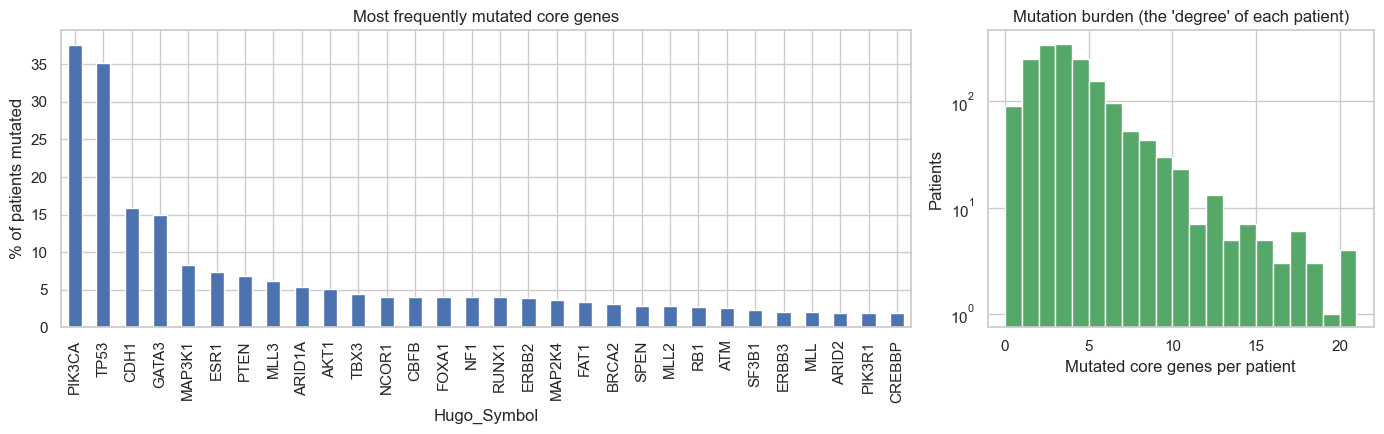

In [3]:
freq = X_full.sum().sort_values(ascending=False)
burden = X_full.sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2.2, 1]})
(freq.head(30) / len(X_full) * 100).plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_ylabel("% of patients mutated")
axes[0].set_title("Most frequently mutated core genes")
axes[1].hist(burden, bins=range(0, burden.max() + 2), color="#55A868")
axes[1].set_xlabel("Mutated core genes per patient")
axes[1].set_ylabel("Patients")
axes[1].set_title("Mutation burden (the 'degree' of each patient)")
axes[1].set_yscale("log")
plt.tight_layout()
plt.show()

The burden histogram is the reason a naïve co-occurrence count is misleading. The distribution is heavy-tailed, so a few hypermutated tumors are "connected" to dozens of genes at once. In social-network terms they behave like spam accounts that follow everyone.

## 3. Degree-Preserving Null Model (Curveball Algorithm)

The curveball algorithm (Strona et al., *Nat. Commun.* 2014) produces random binary matrices that keep **exactly** the same row sums (each patient's burden) and column sums (each gene's frequency). Each "trade" picks two patients and randomly redistributes the genes that only one of them carries. Repeating this many times samples uniformly from all matrices with those margins.

For every gene pair we compare the observed number of co-mutated patients with its null distribution:
- **z-score** = (observed − null mean) / null SD
- **empirical one-sided p** for co-occurrence (observed ≥ null) and for mutual exclusivity (observed ≤ null)
- **Benjamini–Hochberg q-values** across all pairs

A purely empirical p-value cannot go below 1/(N_NULL+1). With thousands of pairs tested, that floor makes FDR control impossible. Tail p-values therefore come from a binomial moment-matched to each pair's null mean and variance. The cell after the statistics checks that these agree with the raw empirical p-values wherever the empirical p is resolvable.

In [4]:
def curveball_sampler(A, n_samples, burn_in_sweeps=50, thin_sweeps=1, rng=rng):
    # Yield co-occurrence matrices (genes x genes) from margin-preserving random matrices.
    rows = [set(np.flatnonzero(r)) for r in A]
    n_rows, n_cols = A.shape
    active = [i for i, r in enumerate(rows) if 0 < len(r) < n_cols]

    def sweep():
        for _ in range(len(active) // 2):
            i, j = rng.choice(active, 2, replace=False)
            a, b = rows[i], rows[j]
            a_only, b_only = a - b, b - a
            if not a_only or not b_only:
                continue
            pool = np.array(list(a_only | b_only))
            rng.shuffle(pool)
            k = len(a_only)
            shared = a & b
            rows[i] = shared | set(pool[:k].tolist())
            rows[j] = shared | set(pool[k:].tolist())

    for _ in range(burn_in_sweeps):
        sweep()
    for _ in range(n_samples):
        for _ in range(thin_sweeps):
            sweep()
        r_idx = np.repeat(np.arange(n_rows), [len(r) for r in rows])
        c_idx = np.fromiter((c for r in rows for c in r), dtype=int)
        M = csr_matrix((np.ones(len(c_idx)), (r_idx, c_idx)), shape=A.shape)
        yield (M.T @ M).toarray()


def comutation_stats(X, n_null, rng=rng):
    # Observed vs curveball-null co-occurrence for every gene pair in X (patients x genes DataFrame).
    A = X.values.astype(np.int8)
    obs = (A.T.astype(np.int32) @ A).astype(float)
    g = A.shape[1]
    s1 = np.zeros((g, g)); s2 = np.zeros((g, g))
    n_ge = np.zeros((g, g)); n_le = np.zeros((g, g))
    for C in curveball_sampler(A, n_null, rng=rng):
        s1 += C; s2 += C ** 2
        n_ge += C >= obs; n_le += C <= obs
    mean = s1 / n_null
    var = np.maximum(s2 / n_null - mean ** 2, 1e-12)
    z = (obs - mean) / np.sqrt(var)
    # Tail p-values from a binomial moment-matched to each pair's null (mean, variance).
    # The null count is a sum of near-independent patient-level Bernoullis (variance < mean),
    # for which a matched binomial is the standard approximation; it resolves tails far below 1/N_NULL.
    p_bin = np.clip(1 - var / np.maximum(mean, 1e-12), 1e-6, 1)
    n_bin = np.maximum(np.round(mean / p_bin), np.ceil(obs)).astype(int)
    p_bin = np.clip(mean / np.maximum(n_bin, 1), 1e-12, 1)
    p_co = stats.binom.sf(obs - 1, n_bin, p_bin)
    p_ex = stats.binom.cdf(obs, n_bin, p_bin)
    emp_co = (n_ge + 1) / (n_null + 1)
    emp_ex = (n_le + 1) / (n_null + 1)
    return obs, mean, z, p_co, p_ex, emp_co, emp_ex

In [5]:
net_genes = freq[freq >= MIN_FREQ_NETWORK * len(X_full)].index.tolist()
X_net = X_full[net_genes]
print(f"Genes in co-mutation network (>= {MIN_FREQ_NETWORK:.0%} of patients): {len(net_genes)}")

obs, exp_null, Z, P_co, P_ex, E_co, E_ex = cached("comutation_stats", lambda: comutation_stats(X_net, N_NULL))

iu = np.triu_indices(len(net_genes), k=1)
n = len(X_net)
nA = X_net.sum().values
pairs = pd.DataFrame({
    "Gene_A": np.array(net_genes)[iu[0]],
    "Gene_B": np.array(net_genes)[iu[1]],
    "n_A": nA[iu[0]], "n_B": nA[iu[1]],
    "Observed": obs[iu].astype(int),
    "Expected_null": exp_null[iu].round(2),
    "z": Z[iu].round(2),
    "p_cooccur": P_co[iu],
    "p_exclusive": P_ex[iu],
    "p_emp_cooccur": E_co[iu],
    "p_emp_exclusive": E_ex[iu],
})
pairs["q_cooccur"] = multipletests(pairs["p_cooccur"], method="fdr_bh")[1]
pairs["q_exclusive"] = multipletests(pairs["p_exclusive"], method="fdr_bh")[1]

# Classic social-network link-prediction scores, for comparison with the null-adjusted z
union = pairs["n_A"] + pairs["n_B"] - pairs["Observed"]
pairs["Jaccard"] = (pairs["Observed"] / union).round(3)
pairs["Lift"] = (pairs["Observed"] * n / (pairs["n_A"] * pairs["n_B"])).round(2)
inv_log_burden = 1 / np.log(np.maximum(X_net.sum(axis=1).values, 2))
AA = (X_net.values.T * inv_log_burden) @ X_net.values   # Adamic-Adar: shared patients weighted by 1/log(burden)
pairs["Adamic_Adar"] = AA[iu].round(2)

print(f"Gene pairs tested: {len(pairs)}")
print(f"Co-occurring  pairs at q < {FDR}: {(pairs.q_cooccur < FDR).sum()}")
print(f"Mutually exclusive pairs at q < {FDR}: {(pairs.q_exclusive < FDR).sum()}")
print(f"Smallest empirical p with N_NULL={N_NULL}: {1/(N_NULL+1):.1e}  (moment-matched p is used for FDR)")

Genes in co-mutation network (>= 1% of patients): 78


Gene pairs tested: 3003
Co-occurring  pairs at q < 0.1: 11
Mutually exclusive pairs at q < 0.1: 11
Smallest empirical p with N_NULL=2000: 5.0e-04  (moment-matched p is used for FDR)


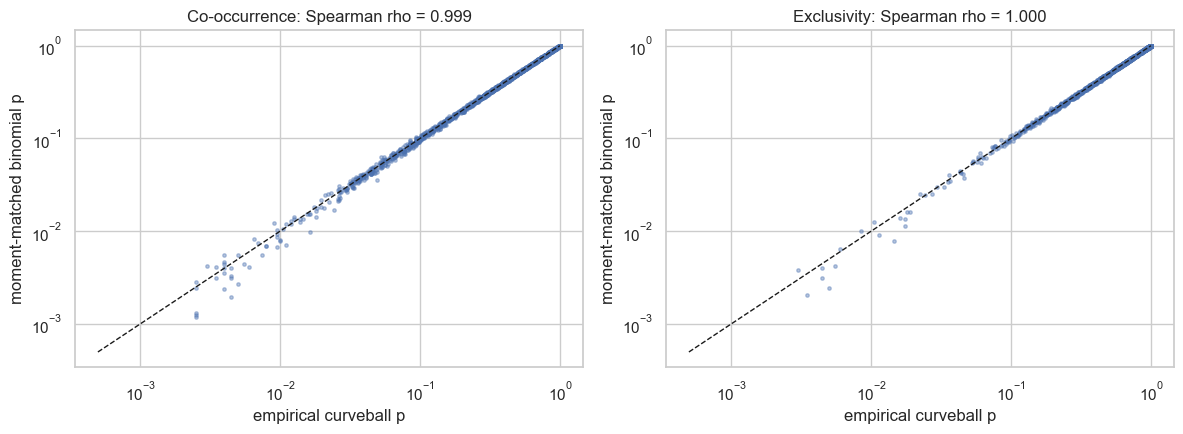

In [6]:
# Calibration: moment-matched vs empirical curveball p-values (only where empirical p is resolvable)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
floor = 1 / (N_NULL + 1)
for ax, a, b, t in [(axes[0], "p_cooccur", "p_emp_cooccur", "Co-occurrence"), (axes[1], "p_exclusive", "p_emp_exclusive", "Exclusivity")]:
    ok = pairs[b] > 5 * floor
    ax.scatter(pairs.loc[ok, b], pairs.loc[ok, a], s=6, alpha=0.4)
    ax.plot([floor, 1], [floor, 1], "k--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("empirical curveball p"); ax.set_ylabel("moment-matched binomial p")
    rho = stats.spearmanr(pairs.loc[ok, a], pairs.loc[ok, b])[0]
    ax.set_title(f"{t}: Spearman rho = {rho:.3f}")
plt.tight_layout()
plt.show()

### Strongest co-occurring pairs (mutate together more than burden and frequency predict)

In [7]:
cols = ["Gene_A", "Gene_B", "n_A", "n_B", "Observed", "Expected_null", "z", "q_cooccur", "Lift", "Jaccard", "Adamic_Adar"]
top_co = pairs[pairs.q_cooccur < FDR].sort_values("z", ascending=False)
top_co[cols].head(25)

,Gene_A,Gene_B,n_A,n_B,Observed,Expected_null,z,q_cooccur,Lift,Jaccard,Adamic_Adar
2585,EP300,STK11,23,20,4,0.32,6.97,0.023393,15.13,0.103,2.17
166,CDH1,ERBB2,277,67,35,12.91,6.87,0.000004,3.28,0.113,25.82
2868,TET2,SETD2,21,20,4,0.33,6.66,0.024040,16.57,0.108,2.03
2554,RICTOR,BRCA1,23,20,4,0.34,6.34,0.083037,15.13,0.103,2.41
1261,FAT1,RICTOR,58,23,6,1.01,5.11,0.093284,7.83,0.080,3.26
160,CDH1,TBX3,277,78,33,15.19,5.06,0.004152,2.66,0.102,22.29
3,PIK3CA,MAP3K1,655,144,87,60.61,4.71,0.002409,1.60,0.122,69.42
236,GATA3,CBFB,260,71,27,13.20,4.29,0.029745,2.54,0.089,21.28
97,TP53,RB1,613,46,32,18.07,4.26,0.015858,1.97,0.051,23.86
261,GATA3,MEN1,260,27,13,4.79,4.09,0.096464,3.22,0.047,12.59


### Strongest mutually exclusive pairs (mutate together *less* than expected)

In [8]:
cols_ex = ["Gene_A", "Gene_B", "n_A", "n_B", "Observed", "Expected_null", "z", "q_exclusive"]
top_ex = pairs[pairs.q_exclusive < FDR].sort_values("z")
top_ex[cols_ex].head(25)

,Gene_A,Gene_B,n_A,n_B,Observed,Expected_null,z,q_exclusive
78,TP53,GATA3,613,260,31,100.71,-9.42,4.006499e-20
77,TP53,CDH1,613,277,49,107.68,-8.01,2.807202e-13
8,PIK3CA,AKT1,655,88,7,37.70,-6.84,1.375692e-10
0,PIK3CA,TP53,655,613,180,243.09,-6.80,1.297676e-08
153,CDH1,GATA3,277,260,13,48.71,-6.26,2.807909e-09
80,TP53,ESR1,613,129,17,50.37,-6.10,3.006556e-08
27,PIK3CA,PIK3R1,655,34,1,14.58,-4.82,4.220371e-05
79,TP53,MAP3K1,613,144,31,56.90,-4.57,7.215816e-04
5,PIK3CA,PTEN,655,118,27,49.70,-4.44,1.501036e-03
87,TP53,CBFB,613,71,11,28.10,-4.18,2.554240e-03


### Raw popularity versus null-adjusted scores

This shows how much the ranking changes once the null model is applied. Raw counts and Jaccard reward common genes. The z-score asks only whether the overlap is *surprising*.

In [9]:
rank_corr = pairs[["Observed", "Jaccard", "Lift", "Adamic_Adar", "z"]].corr(method="spearman")["z"].drop("z")
print("Spearman correlation of each heuristic score with the null-adjusted z:")
print(rank_corr.round(2).to_string())

top_raw = set(pairs.nlargest(20, "Observed")[["Gene_A", "Gene_B"]].apply(tuple, axis=1))
top_z = set(pairs.nlargest(20, "z")[["Gene_A", "Gene_B"]].apply(tuple, axis=1))
print(f"\nOverlap between top-20 pairs by raw count and top-20 by z: {len(top_raw & top_z)} / 20")

Spearman correlation of each heuristic score with the null-adjusted z:
Observed       0.62
Jaccard        0.85
Lift           0.90
Adamic_Adar    0.60

Overlap between top-20 pairs by raw count and top-20 by z: 3 / 20


## 4. Community Detection — Gene Clusters That Mutate Together

Only 11 pairs pass FDR, which is too few edges to show cluster structure. The clustering network is therefore **exploratory**: it keeps an edge where co-occurrence beats the null at nominal p < `EDGE_P` (0.01), weighted by z. Noise is controlled in the next step by checking whether each cluster survives patient bootstraps. In the network plot, FDR-significant edges are drawn in bold. Three standard social community-detection algorithms are run on it and compared:

- **Louvain** modularity maximization (Blondel et al. 2008), the default on most social-graph platforms
- **Greedy modularity** (Clauset–Newman–Moore)
- **Label propagation** (Raghavan et al. 2007), which works like rumor spreading: each node adopts its neighbors' majority label

Agreement between methods is measured with adjusted Rand index (ARI) and normalized mutual information (NMI). Genes with no significant edge are left as singletons and excluded from the comparison.

In [10]:
def build_network(pairs_df, genes, edge_p=EDGE_P):
    G = nx.Graph()
    G.add_nodes_from(genes)
    sig = pairs_df[(pairs_df["p_cooccur"] < edge_p) & (pairs_df["z"] > 0)]
    G.add_weighted_edges_from(sig[["Gene_A", "Gene_B", "z"]].itertuples(index=False, name=None))
    return G


def partition_labels(communities, nodes):
    lab = {g: i for i, c in enumerate(communities) for g in c}
    return np.array([lab[g] for g in nodes])


G = build_network(pairs, net_genes)
connected = [g for g in G.nodes if G.degree(g) > 0]
H = G.subgraph(connected)
print(f"Network: {H.number_of_nodes()} connected genes, {H.number_of_edges()} co-mutation edges at p < {EDGE_P} "
      f"({len(net_genes) - len(connected)} isolated genes)")

methods = {
    "Louvain": nx.community.louvain_communities(H, weight="weight", seed=SEED),
    "Greedy modularity": nx.community.greedy_modularity_communities(H, weight="weight"),
    "Label propagation": list(nx.community.asyn_lpa_communities(H, weight="weight", seed=SEED)),
}
labels = {k: partition_labels(v, connected) for k, v in methods.items()}

summary = pd.DataFrame({
    k: {"n_communities": len(v),
        "modularity": nx.community.modularity(H, v, weight="weight"),
        "largest": max(len(c) for c in v)}
    for k, v in methods.items()
}).T
names = list(methods)
agree = pd.DataFrame([(a, b, adjusted_rand_score(labels[a], labels[b]), normalized_mutual_info_score(labels[a], labels[b]))
                      for i, a in enumerate(names) for b in names[i + 1:]],
                     columns=["Method_A", "Method_B", "ARI", "NMI"]).round(3)
display(summary.round(3))
display(agree)

Network: 59 connected genes, 64 co-mutation edges at p < 0.01 (19 isolated genes)


,n_communities,modularity,largest
Louvain,9.0,0.719,11.0
Greedy modularity,9.0,0.719,11.0
Label propagation,16.0,0.640,10.0


,Method_A,Method_B,ARI,NMI
0,Louvain,Greedy modularity,1.000,1.000
1,Louvain,Label propagation,0.485,0.824
2,Greedy modularity,Label propagation,0.485,0.824


### Stability: do the clusters survive resampling patients?

A cluster that disappears when you resample the cohort is noise. The step below repeats the whole pipeline (curveball null → edges → Louvain) on **N_BOOT** bootstrap resamples of patients and records how often each gene pair lands in the same community. The result is a *consensus matrix*.

In [11]:
def bootstrap_consensus():
    consensus = pd.DataFrame(0.0, index=connected, columns=connected)
    both_present = pd.DataFrame(0.0, index=connected, columns=connected)

    for b in range(N_BOOT):
        idx = rng.choice(len(X_net), len(X_net), replace=True)
        Xb = X_net.iloc[idx].reset_index(drop=True)
        Xb = Xb.loc[:, Xb.sum() > 0]
        gb = Xb.columns.tolist()
        ob, _, zb, pcb, *_ = comutation_stats(Xb, N_NULL_BOOT)
        iub = np.triu_indices(len(gb), k=1)
        pb = pd.DataFrame({"Gene_A": np.array(gb)[iub[0]], "Gene_B": np.array(gb)[iub[1]],
                           "z": zb[iub], "p_cooccur": pcb[iub]})
        Gb = build_network(pb, gb)
        Gb = Gb.subgraph([g for g in Gb if Gb.degree(g) > 0])
        lab = {g: i for i, c in enumerate(nx.community.louvain_communities(Gb, weight="weight", seed=SEED + b)) for g in c}
        present = [g for g in connected if g in lab]
        v = pd.Series({g: lab[g] for g in present})
        same = (v.values[:, None] == v.values[None, :]).astype(float)
        consensus.loc[present, present] += same
        both_present.loc[present, present] += 1

    return (consensus / both_present.replace(0, np.nan)).fillna(0)


consensus = cached("bootstrap_consensus", bootstrap_consensus)

louvain = sorted(methods["Louvain"], key=len, reverse=True)
community_of = {g: i + 1 for i, c in enumerate(louvain) for g in c}

rows = []
for i, c in enumerate(louvain, start=1):
    c = sorted(c, key=lambda g: -freq[g])
    sub = consensus.loc[c, c].values
    within = sub[np.triu_indices(len(c), k=1)].mean() if len(c) > 1 else np.nan
    rows.append({"Community": i, "Size": len(c), "Bootstrap co-assignment": round(within, 2),
                 "Genes (most frequent first)": ", ".join(c)})
communities_df = pd.DataFrame(rows)
communities_df

,Community,Size,Bootstrap co-assignment,Genes (most frequent first)
0,1,11,0.25,"SPEN, MLL2, FLT4, NOTCH2, PTPRT, NOTCH4, APC, ROS1, DNMT3A, ERBB4, FOXP1"
1,2,11,0.26,"FAT1, ATM, CREBBP, NOTCH1, EP300, RICTOR, TET2, STK11, IGF1R, SETD2, BRCA1"
2,3,9,0.28,"TP53, NCOR1, NF1, RB1, PIK3R1, NSD1, MED12, TET1, CDKN2A"
3,4,8,0.60,"PIK3CA, CDH1, MAP3K1, TBX3, FOXA1, RUNX1, ERBB2, CDKN1B"
4,5,8,0.17,"AKT1, ERBB3, ATR, CTCF, ARID1B, PIK3CG, CARD11, PDGFRA"
5,6,4,0.35,"ARID2, PTPRS, EPHA5, TSC2"
6,7,3,0.24,"MLL3, BRCA2, PTCH1"
7,8,3,0.82,"GATA3, CBFB, MEN1"
8,9,2,0.68,"PTEN, SF3B1"


*Bootstrap co-assignment* is the average fraction of resamples in which two genes from the community were placed in the same community again (1.0 = always together). Values well above about 0.5 indicate a reproducible cluster. Low values indicate a community held together by a few patients.

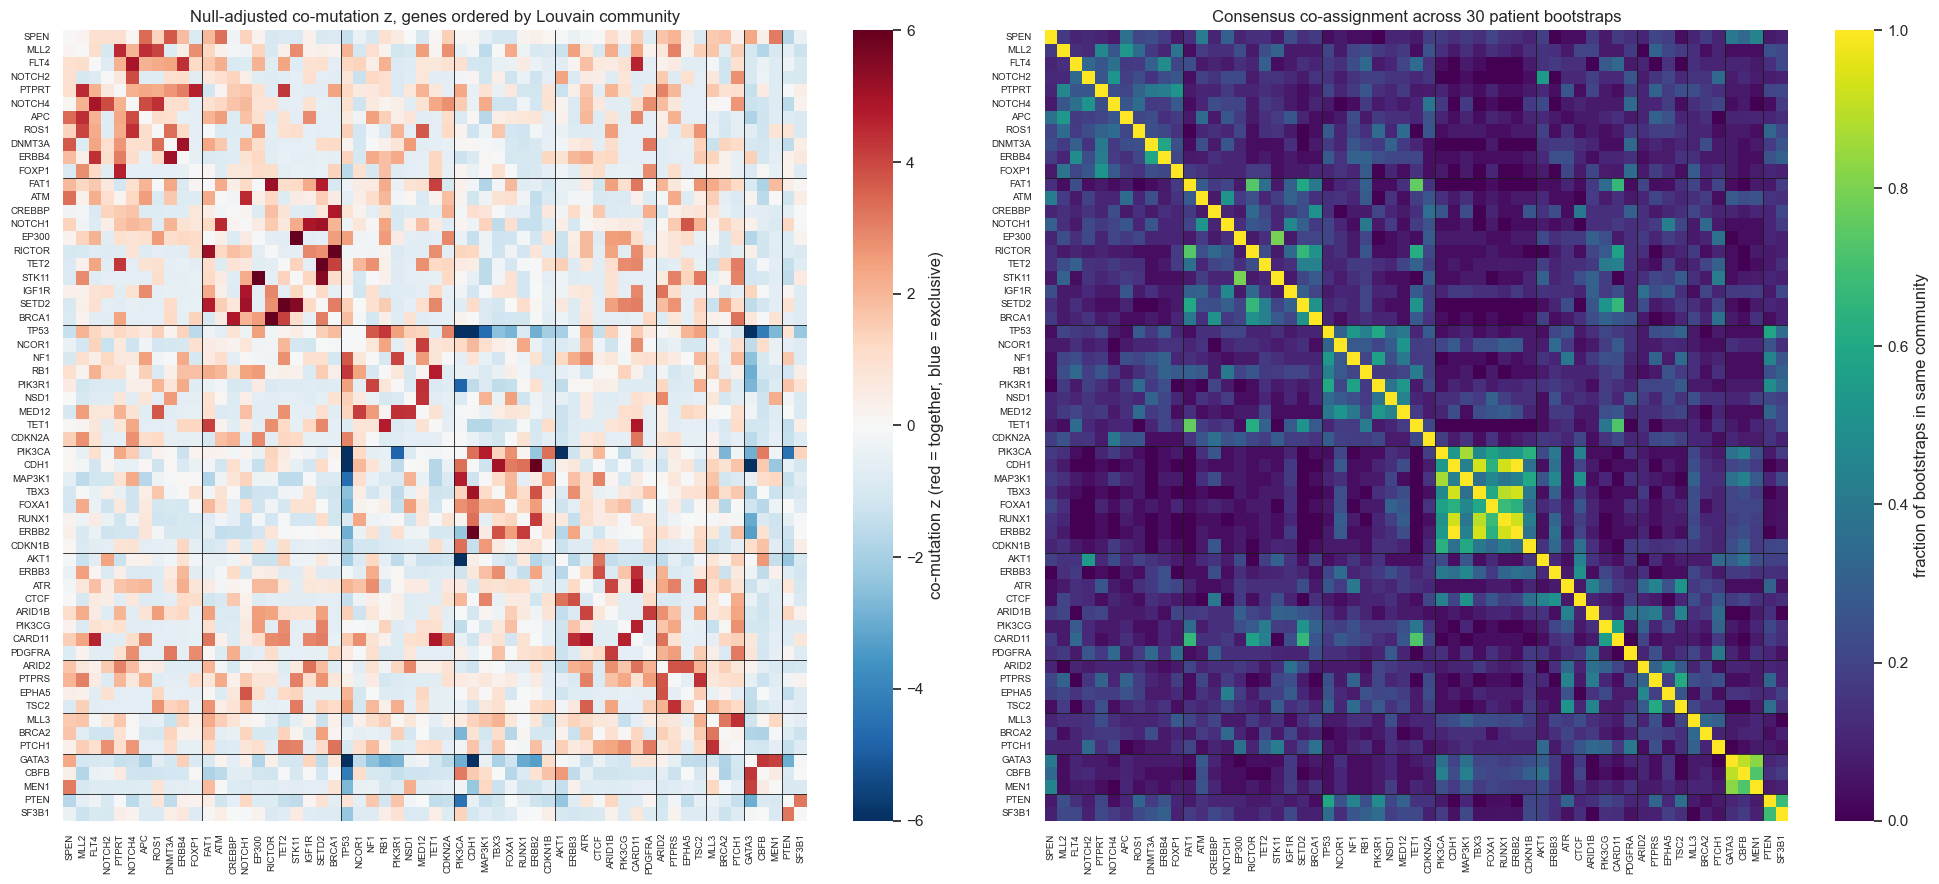

In [12]:
order = [g for c in louvain for g in sorted(c, key=lambda g: -freq[g])]
Zdf = pd.DataFrame(Z, index=net_genes, columns=net_genes)
fig, axes = plt.subplots(1, 2, figsize=(20, 9))

sns.heatmap(Zdf.loc[order, order].clip(-6, 6), cmap="RdBu_r", center=0, ax=axes[0],
            cbar_kws={"label": "co-mutation z (red = together, blue = exclusive)"}, xticklabels=True, yticklabels=True)
axes[0].set_title("Null-adjusted co-mutation z, genes ordered by Louvain community")
sns.heatmap(consensus.loc[order, order], cmap="viridis", vmin=0, vmax=1, ax=axes[1],
            cbar_kws={"label": "fraction of bootstraps in same community"}, xticklabels=True, yticklabels=True)
axes[1].set_title(f"Consensus co-assignment across {N_BOOT} patient bootstraps")
for ax in axes:
    ax.tick_params(labelsize=7)
    edges = np.cumsum([len(c) for c in louvain])[:-1]
    for e in edges:
        ax.axhline(e, color="k", lw=0.6); ax.axvline(e, color="k", lw=0.6)
plt.tight_layout()
plt.show()

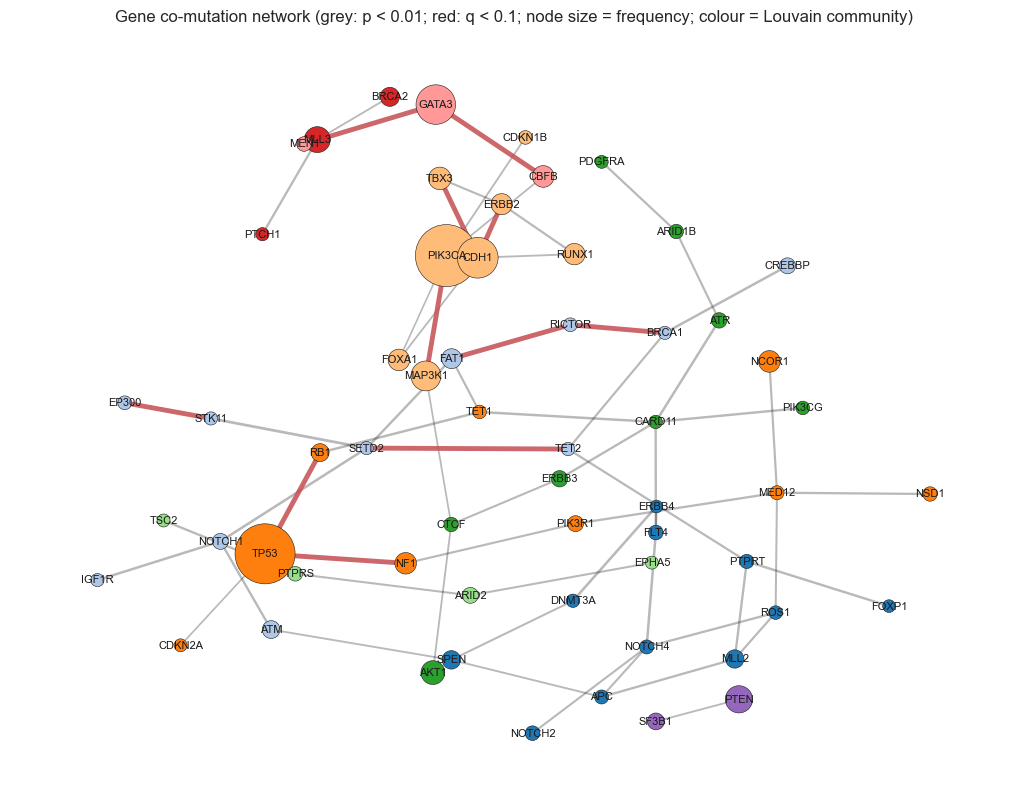

In [13]:
pos = nx.spring_layout(H, weight="weight", seed=SEED, k=0.6)
palette = sns.color_palette("tab20", len(louvain))
fig, ax = plt.subplots(figsize=(13, 10))
fdr_edges = set(top_co[["Gene_A", "Gene_B"]].apply(frozenset, axis=1))
is_fdr = [frozenset(e) in fdr_edges for e in H.edges]
w = np.array([d["weight"] for _, _, d in H.edges(data=True)])
nx.draw_networkx_edges(H, pos, edgelist=[e for e, f in zip(H.edges, is_fdr) if not f],
                       width=(0.4 + 2.0 * w / w.max())[~np.array(is_fdr)], alpha=0.3, ax=ax)
nx.draw_networkx_edges(H, pos, edgelist=[e for e, f in zip(H.edges, is_fdr) if f],
                       width=3.5, edge_color="#C44E52", alpha=0.85, ax=ax)
nx.draw_networkx_nodes(H, pos, node_size=[30 + 3 * freq[g] for g in H],
                       node_color=[palette[community_of[g] - 1] for g in H], edgecolors="k", linewidths=0.4, ax=ax)
nx.draw_networkx_labels(H, pos, font_size=8, ax=ax)
ax.set_title(f"Gene co-mutation network (grey: p < {EDGE_P}; red: q < {FDR}; node size = frequency; colour = Louvain community)")
ax.axis("off")
plt.show()

### Cluster diagrams

The heatmaps and network above show every gene at once. The four diagrams below focus on the clusters themselves:

1. **Cluster map:** all clustered genes on a circle, grouped by community. It shows co-mutation inside clusters *and* mutual exclusivity between them.
2. **Cluster-to-cluster relationships:** average co-mutation z between every pair of communities.
3. **Inside each stable cluster:** the edges holding each reproducible cluster together, labelled observed / expected patients.
4. **Oncoprints:** the actual patients in each stable cluster, one column per patient.

Only clusters that hold up under bootstrap (co-assignment ≥ `STABLE_MIN`) get a colour. The rest are drawn in grey so they don't compete for attention. The three colours are a colorblind-safe set. Line *style*, not colour, separates co-mutation (solid) from exclusivity (dashed).

In [14]:
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

STABLE_MIN = 0.5
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]          # categorical slots 1-3, validated colorblind-safe as a set
INK, INK_2, MUTED, SURFACE = "#0b0b0b", "#52514e", "#c3c2b7", "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list("blue_gray_red", ["#2a78d6", SURFACE, "#e34948"])

stable = communities_df[communities_df["Bootstrap co-assignment"] >= STABLE_MIN]
stable_ids = stable["Community"].tolist()
if len(stable_ids) > len(SERIES):
    print(f"{len(stable_ids)} stable clusters; colouring the {len(SERIES)} most reproducible, the rest stay grey")
    stable_ids = stable.nlargest(len(SERIES), "Bootstrap co-assignment")["Community"].sort_values().tolist()
cluster_color = {cid: SERIES[i] for i, cid in enumerate(stable_ids)}


def cluster_genes(cid):
    return sorted(louvain[cid - 1], key=lambda g: -freq[g])


def cluster_name(cid, n=3):
    g = cluster_genes(cid)
    return f"C{cid} " + "/".join(g[:n]) + ("…" if len(g) > n else "")


def gene_color(g):
    return cluster_color.get(community_of.get(g), MUTED)


print("Stable clusters (coloured):")
for cid in stable_ids:
    print(f"  {cluster_name(cid, 10)}  — bootstrap co-assignment "
          f"{communities_df.set_index('Community').loc[cid, 'Bootstrap co-assignment']:.2f}")

Stable clusters (coloured):
  C4 PIK3CA/CDH1/MAP3K1/TBX3/FOXA1/RUNX1/ERBB2/CDKN1B  — bootstrap co-assignment 0.60
  C8 GATA3/CBFB/MEN1  — bootstrap co-assignment 0.82
  C9 PTEN/SF3B1  — bootstrap co-assignment 0.68


#### 1. Cluster map

Genes sit on the circle grouped by Louvain community. A coloured arc marks each stable cluster. Genes that are in no cluster but take part in a significant exclusivity pair (ESR1, for example) are added as an *unclustered* group so their relationships stay visible.

- **Solid lines:** co-mutation edges from the clustering network (p < `EDGE_P`). Thick black lines pass FDR.
- **Dashed lines:** FDR-significant mutual exclusivity.

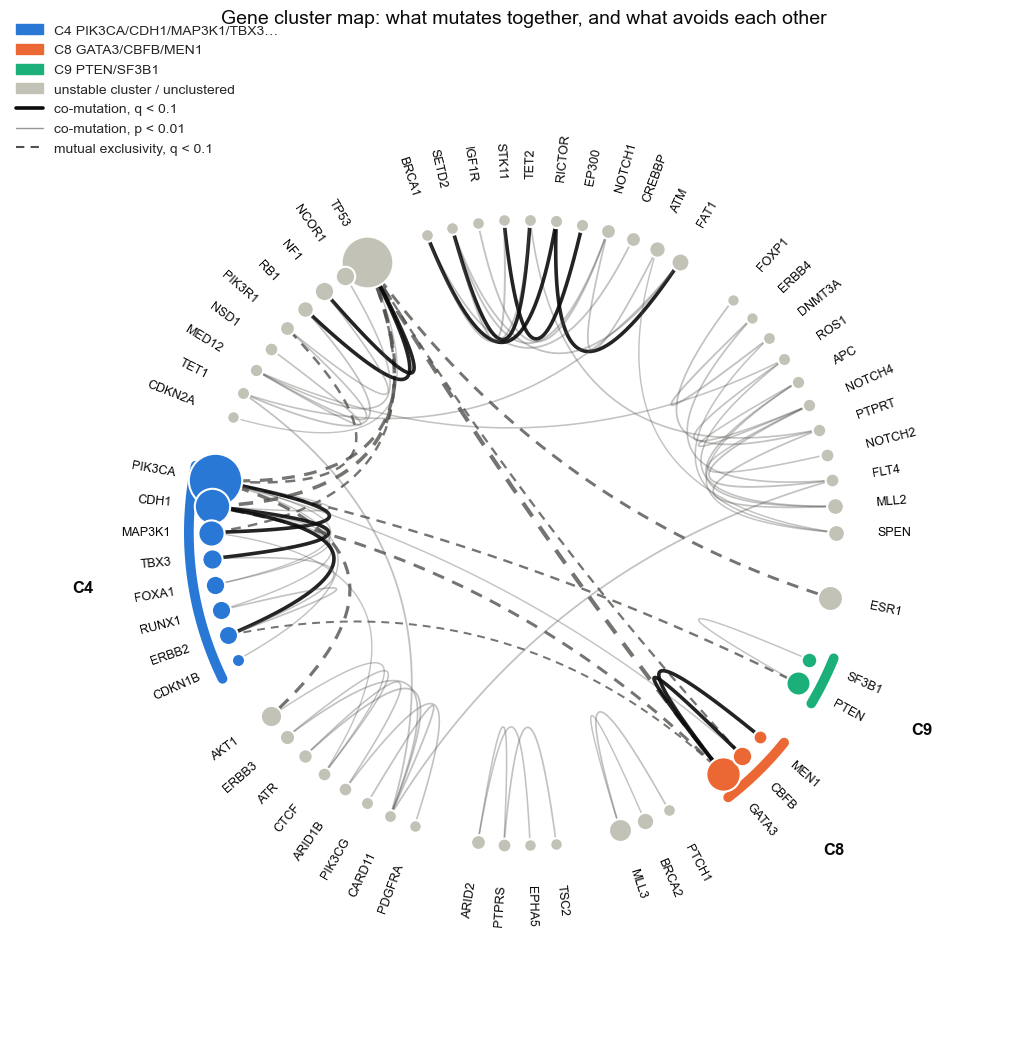

In [15]:
def bezier(p0, p1, pull=0.25, n=40):
    # Quadratic curve bowed toward the centre, as in a chord diagram
    c = (p0 + p1) / 2 * pull
    t = np.linspace(0, 1, n)[:, None]
    return (1 - t) ** 2 * p0 + 2 * (1 - t) * t * c + t ** 2 * p1


groups = [cluster_genes(i + 1) for i in range(len(louvain))]
excl_genes = set(top_ex["Gene_A"]) | set(top_ex["Gene_B"])
unclustered = sorted(excl_genes - set(community_of), key=lambda g: -freq[g])
if unclustered:
    groups.append(unclustered)

gap = 1.5                                              # empty slots between groups
slots, ring = [], []
cursor = 0.0
for gi, grp in enumerate(groups):
    ring.append((cursor, cursor + len(grp) - 1, gi))
    slots += [(g, cursor + k) for k, g in enumerate(grp)]
    cursor += len(grp) + gap
total = cursor
angle = {g: 2 * np.pi * s / total for g, s in slots}
xy = {g: np.array([np.cos(a), np.sin(a)]) for g, a in angle.items()}

fig, ax = plt.subplots(figsize=(13, 13))
ax.set_aspect("equal"); ax.axis("off")

# Co-mutation edges (solid); FDR-significant ones bold
fdr_co = set(top_co[["Gene_A", "Gene_B"]].apply(frozenset, axis=1))
for a, b, d in H.edges(data=True):
    if a in xy and b in xy:
        sig = frozenset((a, b)) in fdr_co
        pts = bezier(xy[a], xy[b])
        ax.plot(*pts.T, color=INK if sig else INK_2, lw=2.6 if sig else 0.5 + d["weight"] / 6,
                alpha=0.9 if sig else 0.35, solid_capstyle="round", zorder=2)

# Mutual exclusivity edges (dashed)
for a, b, z in top_ex[["Gene_A", "Gene_B", "z"]].itertuples(index=False):
    if a in xy and b in xy:
        pts = bezier(xy[a], xy[b])
        ax.plot(*pts.T, color=INK_2, lw=0.6 + abs(z) / 4, ls=(0, (4, 3)), alpha=0.8, zorder=1)

# Cluster arcs
for start, end, gi in ring:
    cid = gi + 1
    if cid in cluster_color:
        th = np.linspace(2 * np.pi * (start - 0.4) / total, 2 * np.pi * (end + 0.4) / total, 60)
        ax.plot(1.07 * np.cos(th), 1.07 * np.sin(th), color=cluster_color[cid], lw=7, solid_capstyle="round")
        mid = (th[0] + th[-1]) / 2
        ax.text(1.42 * np.cos(mid), 1.42 * np.sin(mid), f"C{cid}", color=INK, fontsize=12, fontweight="bold",
                ha="center", va="center")

# Gene nodes (2px surface ring) and radial labels
for g, p in xy.items():
    ax.scatter(*p, s=40 + 2.2 * freq[g], color=gene_color(g), edgecolor="white", linewidth=1.5, zorder=3)
    a = np.degrees(angle[g])
    flip = 90 < a < 270
    ax.text(*(1.13 * p), g, rotation=a + 180 if flip else a, rotation_mode="anchor",
            ha="right" if flip else "left", va="center", fontsize=9, color=INK)

legend = [Patch(color=cluster_color[c], label=cluster_name(c, 4)) for c in stable_ids]
legend += [Patch(color=MUTED, label="unstable cluster / unclustered"),
           Line2D([], [], color=INK, lw=2.6, label=f"co-mutation, q < {FDR}"),
           Line2D([], [], color=INK_2, lw=1, alpha=0.6, label=f"co-mutation, p < {EDGE_P}"),
           Line2D([], [], color=INK_2, lw=1.5, ls=(0, (4, 3)), label=f"mutual exclusivity, q < {FDR}")]
ax.legend(handles=legend, loc="upper left", bbox_to_anchor=(-0.02, 1.02), frameon=False, fontsize=10)
ax.set_xlim(-1.6, 1.6); ax.set_ylim(-1.6, 1.6)
ax.set_title("Gene cluster map: what mutates together, and what avoids each other", fontsize=14, color=INK)
plt.show()

#### 2. How the clusters relate to each other

Each cell is the mean null-adjusted z over all gene pairs between two communities. The diagonal is the cluster's internal cohesion. Red means the clusters' genes tend to mutate together; blue means they tend to avoid each other. Numbers are printed in every cell, so colour is never the only cue.

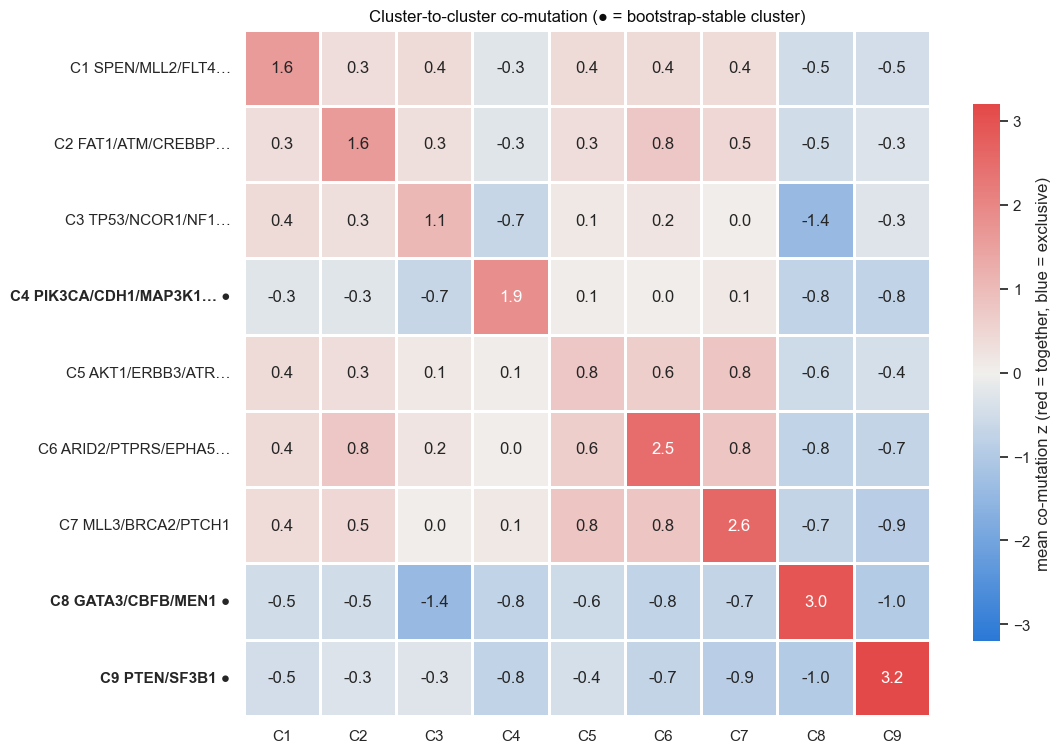

In [16]:
cids = list(range(1, len(louvain) + 1))
between = pd.DataFrame(index=cids, columns=cids, dtype=float)
for a in cids:
    for b in cids:
        ga, gb = cluster_genes(a), cluster_genes(b)
        block = Zdf.loc[ga, gb].values
        if a == b:
            block = block[np.triu_indices(len(ga), k=1)] if len(ga) > 1 else np.array([np.nan])
        between.loc[a, b] = np.nanmean(block)
labels_cc = [cluster_name(c) + (" ●" if c in cluster_color else "") for c in cids]
lim = np.nanmax(np.abs(between.values))

fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(between.astype(float), cmap=DIVERGING, center=0, vmin=-lim, vmax=lim, annot=True, fmt=".1f",
            linewidths=2, linecolor="white", square=True, xticklabels=[f"C{c}" for c in cids], yticklabels=labels_cc,
            cbar_kws={"label": "mean co-mutation z (red = together, blue = exclusive)", "shrink": 0.7}, ax=ax)
for t in ax.get_yticklabels():
    cid = int(t.get_text().split()[0][1:])
    if cid in cluster_color:
        t.set_fontweight("bold")
ax.set_title("Cluster-to-cluster co-mutation (● = bootstrap-stable cluster)", color=INK)
plt.tight_layout()
plt.show()

#### 3. Inside each stable cluster

Each stable cluster is drawn on its own with every co-mutation edge (p < `EDGE_P`) that holds it together. Edge labels show **observed / expected** co-mutated patients under the curveball null. Bold edges pass FDR. Node size is cohort frequency.

In [ ]:
fig, axes = plt.subplots(1, len(stable_ids), figsize=(6.5 * len(stable_ids), 6.5), squeeze=False)
obs_df = pd.DataFrame(obs, index=net_genes, columns=net_genes)
exp_df = pd.DataFrame(exp_null, index=net_genes, columns=net_genes)
for ax, cid in zip(axes[0], stable_ids):
    genes_c = cluster_genes(cid)
    sub = H.subgraph(genes_c)
    p = nx.spring_layout(sub, weight=None, seed=SEED, k=2.0) if sub.number_of_edges() else nx.circular_layout(sub)
    for a, b, d in sub.edges(data=True):
        sig = frozenset((a, b)) in fdr_co
        ax.plot(*zip(p[a], p[b]), color=INK if sig else INK_2, lw=3 if sig else 1.2, alpha=0.9 if sig else 0.5, zorder=1)
        mid = (p[a] + p[b]) / 2
        ax.text(*mid, f"{obs_df.loc[a, b]:.0f} / {exp_df.loc[a, b]:.1f}", fontsize=8.5, color=INK_2, ha="center",
                va="center", bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.9), zorder=2)
    for g in genes_c:
        ax.scatter(*p[g], s=200 + 4 * freq[g], color=cluster_color[cid], edgecolor="white", linewidth=2, zorder=3)
        ax.text(p[g][0], p[g][1] - (0.08 + 0.006 * np.sqrt(freq[g])), f"{g}\n{freq[g] / len(X_full):.1%}", ha="center", va="top", fontsize=9.5,
                color=INK, zorder=4)
    score = communities_df.set_index("Community").loc[cid, "Bootstrap co-assignment"]
    ax.set_title(f"C{cid} — bootstrap co-assignment {score:.2f}", color=INK)
    ax.margins(0.25); ax.axis("off")
fig.suptitle("Stable gene clusters (edge label = observed / expected co-mutated patients; bold = q < FDR)", color=INK)
plt.tight_layout()
plt.show()

#### 4. Oncoprints: the patients behind each cluster

One column per patient carrying at least one mutation in the cluster, one row per gene. Columns are sorted so that patients sharing a pattern sit next to each other. Co-mutation shows up as columns filled in several rows at once; exclusivity shows up as a "staircase". The top track gives the patient's hormone-receptor status, since Section 5 shows the clusters are subtype-linked.

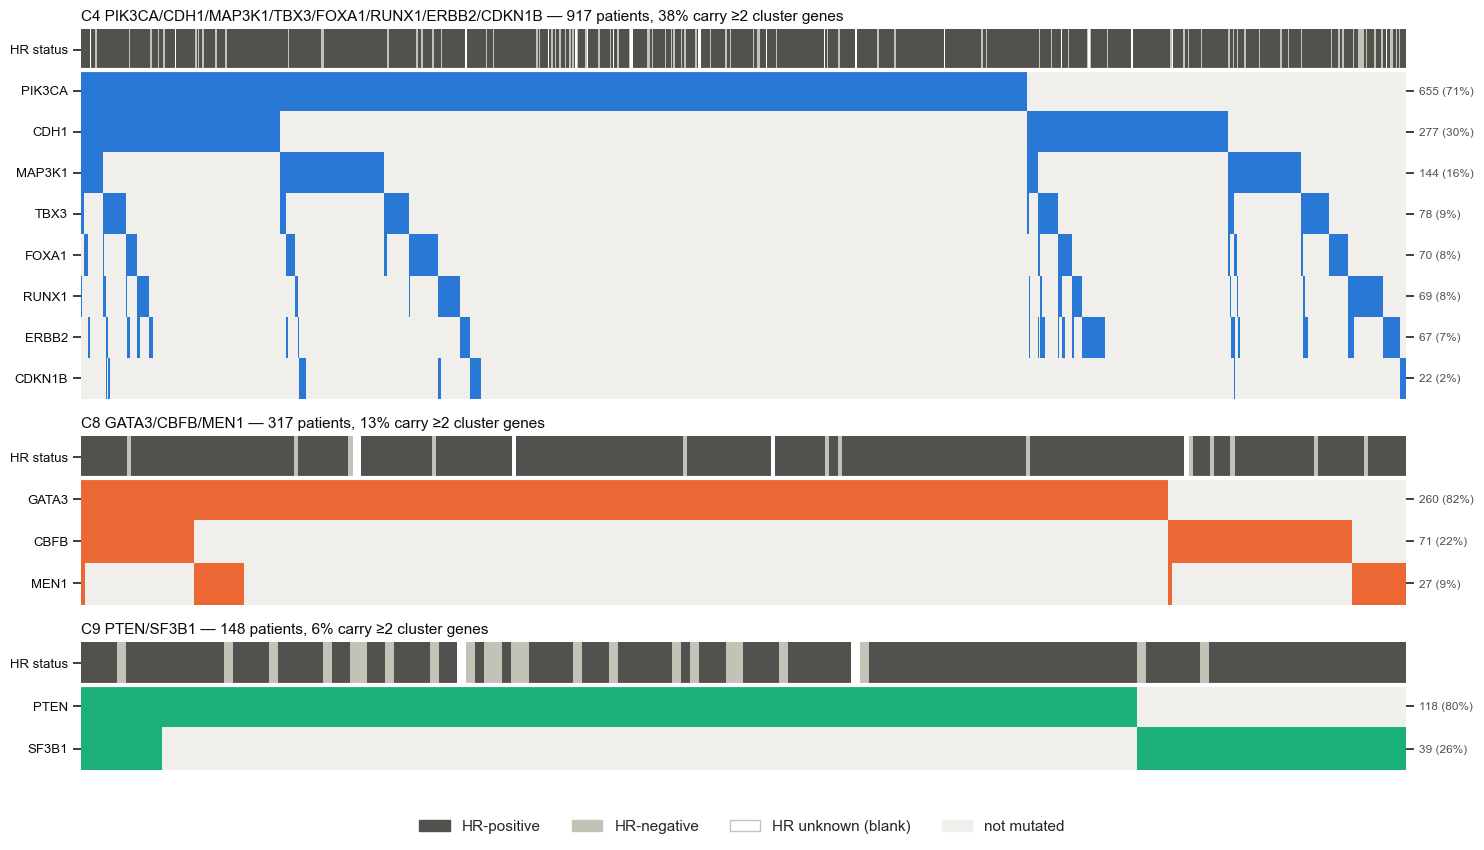

In [18]:
hr = samples.loc[X_full.index, "HR_STATUS"]
hr_code = {"Positive": 2, "Negative": 1}
heights = [len(cluster_genes(c)) + 1.2 for c in stable_ids]
fig, axes = plt.subplots(len(stable_ids), 1, figsize=(15, 0.42 * sum(heights) + 1.5),
                         gridspec_kw={"height_ratios": heights}, squeeze=False)
for ax, cid in zip(axes[:, 0], stable_ids):
    genes_c = cluster_genes(cid)
    M = X_full[genes_c]
    M = M[M.sum(axis=1) > 0]
    M = M.sort_values(genes_c, ascending=False)          # lexicographic: groups shared patterns
    track = hr.loc[M.index].map(hr_code).fillna(0).values[None, :]
    grid = np.vstack([track + 10, M.T.values])           # row 0 = HR track, then genes
    cmap = ListedColormap([SURFACE, cluster_color[cid]] + ["white"] * 8 + ["white", MUTED, INK_2])
    ax.imshow(grid, aspect="auto", interpolation="nearest", cmap=cmap, vmin=0, vmax=12)
    ax.set_yticks(range(len(genes_c) + 1))
    ax.set_yticklabels(["HR status"] + genes_c, fontsize=9.5, color=INK)
    ax.set_xticks([])
    ax2 = ax.twinx()
    ax2.set_ylim(ax.get_ylim()); ax2.set_yticks(range(1, len(genes_c) + 1))
    ax2.set_yticklabels([f"{M[g].sum()} ({M[g].mean():.0%})" for g in genes_c], fontsize=8.5, color=INK_2)
    ax2.grid(False)
    for s in list(ax.spines.values()) + list(ax2.spines.values()):
        s.set_visible(False)
    ax.grid(False)
    ax.axhline(0.5, color="white", lw=3)
    multi = (M.sum(axis=1) >= 2).mean()
    ax.set_title(f"{cluster_name(cid, 10)} — {len(M)} patients, {multi:.0%} carry ≥2 cluster genes",
                 loc="left", color=INK, fontsize=11)
fig.legend(handles=[Patch(color=INK_2, label="HR-positive"), Patch(color=MUTED, label="HR-negative"),
                    Patch(facecolor="white", edgecolor=MUTED, label="HR unknown (blank)"), Patch(color=SURFACE, label="not mutated")],
           loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## 5. Do the Clusters Map onto Clinical Subtypes?

Each patient is assigned to the gene community in which they carry the most mutations (social analogy: the group a user engages with most). Patients with no mutations in any connected gene are labelled *none*. The assignments are cross-tabulated against hormone-receptor status, histology and sample type. The heatmap shows **standardized Pearson residuals**: positive (red) means the community is over-represented in that clinical group.

Caution: these associations also explain some of the co-mutation edges. For example, if two genes are both enriched in lobular tumors, they will co-occur in a pooled cohort without interacting biologically. The limitations section returns to this.

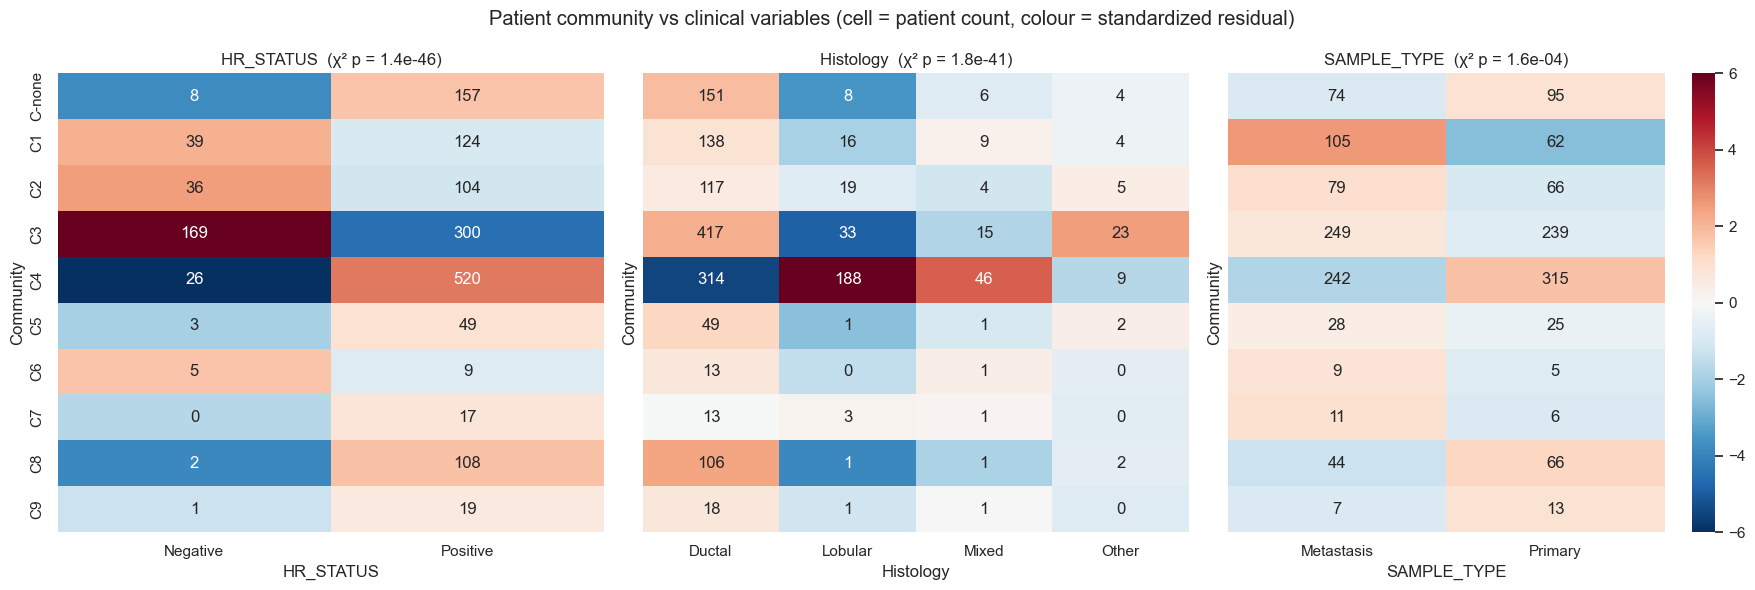

,Variable,chi2,dof,p
0,HR_STATUS,239.9,9,1.358176e-46
1,Histology,267.7,27,1.799292e-41
2,SAMPLE_TYPE,32.5,9,1.624531e-04


In [19]:
comm_counts = pd.DataFrame({i: X_net[[g for g in c if g in X_net]].sum(axis=1) for i, c in enumerate(louvain, start=1)})
patient_comm = comm_counts.idxmax(axis=1).astype(str).where(comm_counts.max(axis=1) > 0, "none")
patient_comm = "C" + patient_comm.where(patient_comm != "none", "-none")

clin = samples[["PATIENT_ID", "HR_STATUS", "CANCER_TYPE_DETAILED", "SAMPLE_TYPE"]].copy()
clin["Histology"] = clin["CANCER_TYPE_DETAILED"].map(
    lambda s: "Lobular" if "Lobular" in s and "Mixed" not in s else
              "Ductal" if "Ductal" in s and "Mixed" not in s else
              "Mixed" if "Mixed" in s else "Other")
clin["Community"] = patient_comm

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
assoc = []
for ax, var in zip(axes, ["HR_STATUS", "Histology", "SAMPLE_TYPE"]):
    sub = clin[~clin[var].isin(["Unk/ND"])]
    ct = pd.crosstab(sub["Community"], sub[var])
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    resid = (ct - expected) / np.sqrt(expected)
    sns.heatmap(resid, annot=ct, fmt="d", cmap="RdBu_r", center=0, vmin=-6, vmax=6, ax=ax, cbar=ax is axes[-1])
    ax.set_title(f"{var}  (χ² p = {p:.1e})")
    assoc.append({"Variable": var, "chi2": round(chi2, 1), "dof": dof, "p": p})
plt.suptitle("Patient community vs clinical variables (cell = patient count, colour = standardized residual)")
plt.tight_layout()
plt.show()
pd.DataFrame(assoc)

## 6. The Recommendation Engine

**Task:** a patient has a set of known mutated genes. Rank all other candidate genes by how likely the patient is to *also* carry a mutation in them. This is the "people who bought X also bought Y" problem. A practical use is prioritizing which genes to look at more closely (orthogonal validation, deeper coverage, germline follow-up) in a new tumor.

Six recommenders, from simplest to most "social":

| Model | Idea |
|---|---|
| **Popularity** | Recommend the most commonly mutated genes. The baseline every other model must beat. |
| **Item-kNN (cosine)** | Amazon-style item-to-item collaborative filtering on gene co-occurrence vectors. |
| **User-kNN (Jaccard, k=50)** | Find the 50 patients whose mutation profiles are most similar and pool their genes. |
| **Personalized PageRank** | Twitter "Who-To-Follow"-style random walk with restart on the patient–gene bipartite graph, starting at the patient's genes. |
| **NMF (latent programs)** | Matrix factorization. Patients are mixtures of latent mutational "programs". |
| **Null-adjusted co-mutation** | Base rate × the curveball-adjusted enrichment of each candidate with each known gene (naïve-Bayes style; uses this notebook's network). |

**Evaluation:** 5-fold cross-validation *over patients*. Each model is fitted (including its own curveball null) on 80% of patients. For every held-out patient with ≥2 mutated candidate genes, one mutated gene is hidden at random, the rest are given to the model, and the rank of the hidden gene is recorded. Metrics: **Hit@3**, **Hit@10** and **MRR** (mean reciprocal rank).

PIK3CA and TP53 together cover most patients, so popularity alone already scores well. The models are therefore also scored on the harder subset where the hidden gene is *not* PIK3CA or TP53. That subset is where co-mutation structure has to do the work.

In [20]:
class Popularity:
    def fit(self, T):
        self.score_ = T.mean(axis=0)
        return self
    def score(self, q):
        return np.tile(self.score_, (len(q), 1))


class ItemKNN:
    def fit(self, T):
        C = T.T @ T
        norm = np.sqrt(np.diag(C))
        S = C / np.outer(norm, norm).clip(1e-12)
        np.fill_diagonal(S, 0)
        self.S_ = S
        self.pop_ = T.mean(axis=0)
        return self
    def score(self, q):
        return q @ self.S_ + 1e-6 * self.pop_   # popularity only breaks ties


class UserKNN:
    def __init__(self, k=50):
        self.k = k
    def fit(self, T):
        self.T_ = T
        self.pop_ = T.mean(axis=0)
        return self
    def score(self, q):
        inter = q @ self.T_.T
        union = q.sum(1)[:, None] + self.T_.sum(1)[None, :] - inter
        sim = inter / union.clip(1)
        out = np.zeros((len(q), self.T_.shape[1]))
        for r in range(len(q)):
            nn = np.argpartition(-sim[r], self.k)[:self.k]
            out[r] = sim[r, nn] @ self.T_[nn]
        return out + 1e-6 * self.pop_


class PersonalizedPageRank:
    # Random walk with restart on the bipartite graph; patients are down-weighted by burden
    # so hypermutated tumors don't act as hubs.
    def __init__(self, alpha=0.5, n_iter=30):
        self.alpha, self.n_iter = alpha, n_iter
    def fit(self, T):
        T = T.astype(float)
        P_gp = T.T / T.sum(axis=1).clip(1)                   # gene -> patient, weighted 1/burden
        P_gp = P_gp / P_gp.sum(axis=1, keepdims=True).clip(1e-12)
        P_pg = T / T.sum(axis=1, keepdims=True).clip(1)      # patient -> gene
        self.M_ = P_gp @ P_pg                                # two-step gene -> gene transition
        self.pop_ = T.mean(axis=0)
        return self
    def score(self, q):
        r0 = q / q.sum(1, keepdims=True).clip(1)
        r = r0.copy()
        for _ in range(self.n_iter):
            r = self.alpha * r0 + (1 - self.alpha) * r @ self.M_
        return r + 1e-6 * self.pop_


class NMFRecommender:
    def __init__(self, n_components=12):
        self.n_components = n_components
    def fit(self, T):
        self.model_ = NMF(self.n_components, init="nndsvda", max_iter=500, random_state=SEED).fit(T)
        self.pop_ = T.mean(axis=0)
        return self
    def score(self, q):
        return self.model_.transform(q) @ self.model_.components_ + 1e-6 * self.pop_


class NullAdjustedCoMutation:
    # score_j = log P(j) + sum_{i in profile} log((obs_ij + a) / (null_ij + a)), shrunk by pseudo-count a
    def __init__(self, n_null=N_NULL_BOOT, pseudo=2.0):
        self.n_null, self.pseudo = n_null, pseudo
    def fit(self, T):
        keep = T.sum(axis=0) > 0
        obs, null_mean, *_ = comutation_stats(pd.DataFrame(T[:, keep]), self.n_null)
        L = np.zeros((T.shape[1], T.shape[1]))
        L[np.ix_(keep, keep)] = np.log((obs + self.pseudo) / (null_mean + self.pseudo))
        np.fill_diagonal(L, 0)
        self.L_ = L
        self.logpop_ = np.log(T.mean(axis=0) + 1e-4)
        return self
    def score(self, q):
        return self.logpop_ + q @ self.L_


MODELS = {
    "Popularity": Popularity,
    "Item-kNN (cosine)": ItemKNN,
    "User-kNN (Jaccard, k=50)": UserKNN,
    "Personalized PageRank": PersonalizedPageRank,
    "NMF (12 programs)": NMFRecommender,
    "Null-adjusted co-mutation": NullAdjustedCoMutation,
}

In [21]:
rec_genes = freq[freq >= MIN_PATIENTS_RECSYS].index.tolist()
R = X_full[rec_genes].values.astype(float)
print(f"Candidate genes for recommendation: {len(rec_genes)}")

def run_cross_validation():
    eval_rng = np.random.default_rng(SEED)
    records = []
    for fold, (tr, te) in enumerate(KFold(5, shuffle=True, random_state=SEED).split(R)):
        T, E = R[tr], R[te]
        E = E[E.sum(axis=1) >= 2]
        hidden = np.array([eval_rng.choice(np.flatnonzero(row)) for row in E])
        Q = E.copy()
        Q[np.arange(len(Q)), hidden] = 0
        for name, cls in MODELS.items():
            S = cls().fit(T).score(Q)
            S = np.where(Q > 0, -np.inf, S)                      # never recommend a known gene
            target = S[np.arange(len(S)), hidden]
            rank = 1 + (S > target[:, None]).sum(axis=1)
            for h, rk in zip(hidden, rank):
                records.append({"Model": name, "fold": fold, "hidden_gene": rec_genes[h], "rank": rk})
        print(f"fold {fold + 1}/5 done: {len(E)} test patients")

    return pd.DataFrame(records)


ev = cached("recsys_cv", run_cross_validation)
ev["hard"] = ~ev["hidden_gene"].isin(["PIK3CA", "TP53"])

def metrics(d):
    return pd.Series({"Hit@3": (d["rank"] <= 3).mean(), "Hit@10": (d["rank"] <= 10).mean(),
                      "MRR": (1 / d["rank"]).mean(), "n": len(d)})

res_all = ev.groupby("Model").apply(metrics, include_groups=False)
res_hard = ev[ev.hard].groupby("Model").apply(metrics, include_groups=False)
results_table = pd.concat({"All hidden genes": res_all, "Hidden gene not PIK3CA/TP53": res_hard}, axis=1)
results_table = results_table.loc[list(MODELS)].round(3)
results_table

Candidate genes for recommendation: 235


fold 1/5 done: 274 test patients


fold 2/5 done: 268 test patients


fold 3/5 done: 282 test patients


fold 4/5 done: 291 test patients


fold 5/5 done: 273 test patients


All hidden genes                        \
                                     Hit@3 Hit@10    MRR       n   
Model                                                              
Popularity                           0.312  0.484  0.266  1388.0   
Item-kNN (cosine)                    0.228  0.377  0.217  1388.0   
User-kNN (Jaccard, k=50)             0.300  0.445  0.270  1388.0   
Personalized PageRank                0.308  0.474  0.275  1388.0   
NMF (12 programs)                    0.086  0.190  0.084  1388.0   
Null-adjusted co-mutation            0.311  0.481  0.280  1388.0   

                          Hidden gene not PIK3CA/TP53                        
                                                Hit@3 Hit@10    MRR       n  
Model                                                                        
Popularity                                      0.108  0.331  0.102  1071.0  
Item-kNN (cosine)                               0.102  0.249  0.107  1071.0  
User-kNN (Jaccard, k=50)                        0.121  0.287  0.114  1071.0  
Personalized PageRank                           0.106  0.318  0.103  1071.0  
NMF (12 programs)                               0.092  0.173  0.086  1071.0  
Null-adjusted co-mutation                       0.120  0.330  0.118  1071.0

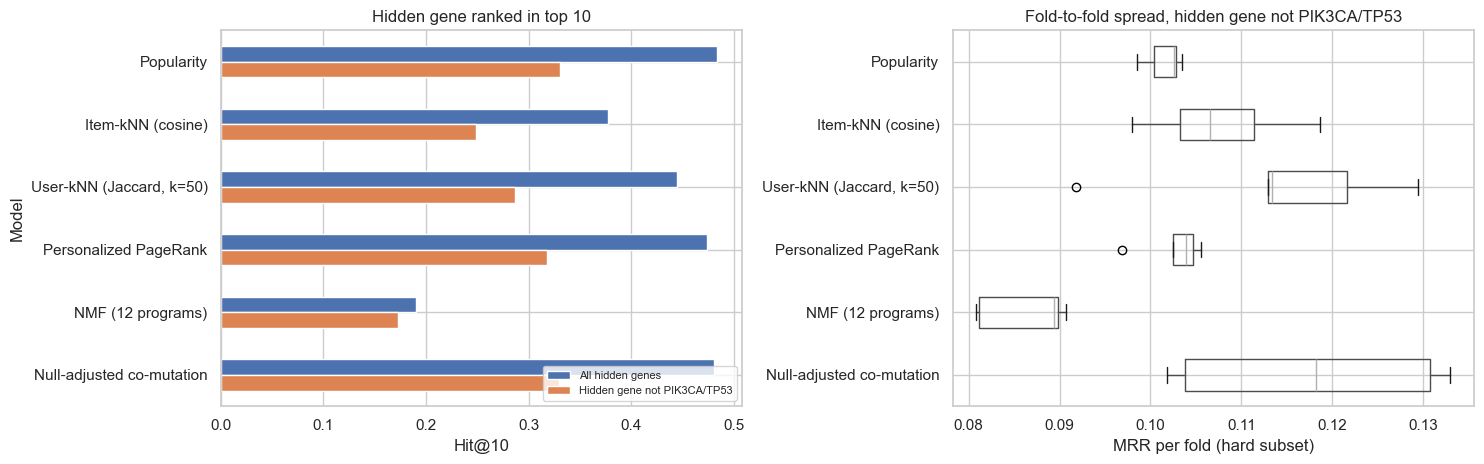

,Model,Mean RR gain vs popularity,95% CI low,95% CI high,Cases improved,Cases worsened
0,Item-kNN (cosine),0.0060,-0.0032,0.0153,0.3660,0.5892
1,"User-kNN (Jaccard, k=50)",0.0123,0.0026,0.0224,0.2325,0.6340
2,Personalized PageRank,0.0012,-0.0033,0.0060,0.3408,0.5546
3,NMF (12 programs),-0.0151,-0.0303,0.0002,0.4062,0.5817
4,Null-adjusted co-mutation,0.0161,0.0077,0.0248,0.4342,0.4893


In [22]:
fold_mrr = ev[ev.hard].groupby(["Model", "fold"]).apply(lambda d: (1 / d["rank"]).mean(), include_groups=False).unstack()
fold_mrr = fold_mrr.loc[list(MODELS)]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
results_table.xs("Hit@10", axis=1, level=1).plot.barh(ax=axes[0])
axes[0].set_xlabel("Hit@10"); axes[0].set_title("Hidden gene ranked in top 10"); axes[0].invert_yaxis()
axes[0].legend(loc="lower right", fontsize=8)
fold_mrr.T.boxplot(ax=axes[1], vert=False)
axes[1].set_xlabel("MRR per fold (hard subset)"); axes[1].set_title("Fold-to-fold spread, hidden gene not PIK3CA/TP53")
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

# Paired comparison vs popularity on the hard subset (same patients, same hidden gene)
ev_hard = ev[ev.hard].copy()
ev_hard["pid"] = ev_hard.groupby("Model").cumcount()
paired = ev_hard.assign(rr=1 / ev_hard["rank"]).pivot(index="pid", columns="Model", values="rr")
# Paired bootstrap over test cases: reciprocal-rank gains are skewed and tie-heavy, so a CI on the mean is more honest than a rank test
boot_rng = np.random.default_rng(SEED)
boot_idx = boot_rng.integers(0, len(paired), size=(2000, len(paired)))
rows = []
for m in MODELS:
    if m == "Popularity":
        continue
    d = (paired[m] - paired["Popularity"]).values
    bm = d[boot_idx].mean(axis=1)
    rows.append({"Model": m, "Mean RR gain vs popularity": d.mean(), "95% CI low": np.percentile(bm, 2.5),
                 "95% CI high": np.percentile(bm, 97.5), "Cases improved": (d > 0).mean(), "Cases worsened": (d < 0).mean()})
pd.DataFrame(rows).round(4)

### Which genes are recommendable?

Per-gene MRR for the best co-mutation model, compared with popularity, shows *which* genes the network structure helps predict. These are the genes whose mutation status is most informative about each other.

In [23]:
per_gene = (ev.assign(rr=1 / ev["rank"]).pivot_table(index="hidden_gene", columns="Model", values="rr", aggfunc="mean"))
per_gene["n_hidden"] = ev[ev.Model == "Popularity"].groupby("hidden_gene").size()
best_model = results_table[("Hidden gene not PIK3CA/TP53", "MRR")].drop("Popularity").idxmax()
per_gene["Gain"] = per_gene[best_model] - per_gene["Popularity"]
print(f"Best non-baseline model on the hard subset: {best_model}")
per_gene[per_gene.n_hidden >= 10].sort_values("Gain", ascending=False)[["n_hidden", "Popularity", best_model, "Gain"]].round(3).head(15)

Best non-baseline model on the hard subset: Null-adjusted co-mutation


Model,n_hidden,Popularity,Null-adjusted co-mutation,Gain
hidden_gene,,,,
NF1,14,0.076,0.269,0.192
CBFB,23,0.083,0.239,0.156
ERBB2,10,0.073,0.208,0.135
FAT1,14,0.058,0.191,0.132
TP53,152,0.625,0.750,0.125
TBX3,19,0.102,0.196,0.094
FOXA1,13,0.082,0.171,0.089
NCOR1,14,0.087,0.159,0.071
CDH1,80,0.454,0.506,0.051


## 7. Using the Engine on a Patient Profile

Edit `query_profile` below to any set of genes and re-run. The engine is refit on the **full** cohort. Each recommendation comes with its evidence: how many patients carrying each known gene also carry the candidate, and the curveball z for that pair. A clinician or researcher can then see *why* a gene was recommended rather than trusting a black-box score.

In [24]:
final_models = {name: cls().fit(R) for name, cls in MODELS.items()}
Zfull = dict(zip(zip(pairs.Gene_A, pairs.Gene_B), pairs.z))
Zfull.update({(b, a): z for (a, b), z in list(Zfull.items())})


def recommend(profile, model=None, top_k=10):
    model = model or best_model
    unknown = [g for g in profile if g not in rec_genes]
    if unknown:
        print(f"Ignored (not a candidate gene): {unknown}")
    q = np.zeros((1, len(rec_genes)))
    q[0, [rec_genes.index(g) for g in profile if g in rec_genes]] = 1
    s = final_models[model].score(q)[0]
    s[q[0] > 0] = -np.inf
    top = np.argsort(-s)[:top_k]
    out = []
    for j in top:
        g = rec_genes[j]
        row = {"Recommended gene": g, "Score": round(float(s[j]), 3), "Cohort freq": f"{freq[g] / len(X_full):.1%}"}
        for k in profile:
            if k in X_full:
                both = int((X_full[k] & X_full[g]).sum())
                z = Zfull.get((k, g))
                row[f"w/ {k}"] = f"{both}/{int(X_full[k].sum())}" + (f" (z={z:+.1f})" if z is not None else "")
        out.append(row)
    return pd.DataFrame(out)


query_profile = ["CDH1"]
print(f"Profile {query_profile} — model: {best_model}")
recommend(query_profile)

Profile ['CDH1'] — model: Null-adjusted co-mutation


,Recommended gene,Score,Cohort freq,w/ CDH1
0,PIK3CA,-0.845,37.6%,138/277 (z=+3.3)
1,TP53,-1.845,35.2%,49/277 (z=-8.0)
2,ERBB2,-2.426,3.9%,35/277 (z=+6.9)
3,TBX3,-2.474,4.5%,33/277 (z=+5.1)
4,MLL3,-2.687,6.1%,26/277 (z=+1.4)
5,ESR1,-2.773,7.4%,22/277 (z=-0.7)
6,FOXA1,-2.781,4.0%,24/277 (z=+3.1)
7,MAP3K1,-2.781,8.3%,22/277 (z=-1.2)
8,RUNX1,-2.836,4.0%,24/277 (z=+3.3)
9,PTEN,-2.855,6.8%,21/277 (z=-0.5)


In [25]:
for profile in (["TP53"], ["PIK3CA", "MAP3K1"], ["ESR1"]):
    print(f"\nProfile {profile} — model: {best_model}")
    display(recommend(profile, top_k=8))


Profile ['TP53'] — model: Null-adjusted co-mutation


,Recommended gene,Score,Cohort freq,w/ TP53
0,PIK3CA,-1.314,37.6%,180/613 (z=-6.8)
1,CDH1,-2.639,15.9%,49/613 (z=-8.0)
2,PTEN,-2.683,6.8%,51/613 (z=+0.8)
3,NF1,-2.856,4.0%,43/613 (z=+3.7)
4,MLL3,-2.996,6.1%,37/613 (z=-1.1)
5,GATA3,-3.092,14.9%,31/613 (z=-9.4)
6,MAP3K1,-3.107,8.3%,31/613 (z=-4.6)
7,RB1,-3.153,2.6%,32/613 (z=+4.3)



Profile ['PIK3CA', 'MAP3K1'] — model: Null-adjusted co-mutation


,Recommended gene,Score,Cohort freq,w/ PIK3CA,w/ MAP3K1
0,CDH1,-1.996,15.9%,138/655 (z=+3.3),22/144 (z=-1.2)
1,TP53,-1.996,35.2%,180/655 (z=-6.8),31/144 (z=-4.6)
2,GATA3,-2.297,14.9%,86/655 (z=-2.9),24/144 (z=-0.4)
3,MLL3,-2.659,6.1%,47/655 (z=+0.5),16/144 (z=+1.7)
4,FOXA1,-2.693,4.0%,40/655 (z=+2.8),12/144 (z=+2.0)
5,TBX3,-2.812,4.5%,39/655 (z=+1.4),11/144 (z=+1.1)
6,CBFB,-2.835,4.1%,42/655 (z=+3.1),10/144 (z=+1.1)
7,ESR1,-2.865,7.4%,52/655 (z=-0.4),12/144 (z=-0.4)



Profile ['ESR1'] — model: Null-adjusted co-mutation


,Recommended gene,Score,Cohort freq,w/ ESR1
0,PIK3CA,-1.070,37.6%,52/129 (z=-0.4)
1,GATA3,-1.909,14.9%,25/129 (z=+0.4)
2,CDH1,-2.010,15.9%,22/129 (z=-0.7)
3,TP53,-2.121,35.2%,17/129 (z=-6.1)
4,MAP3K1,-2.662,8.3%,12/129 (z=-0.4)
5,ARID1A,-2.913,5.3%,10/129 (z=+0.5)
6,MLL3,-2.925,6.1%,9/129 (z=-0.4)
7,FAT1,-3.050,3.3%,9/129 (z=+1.6)


## 8. Save Results

In [26]:
pairs.to_csv("results/social_comutation_pairs.csv", index=False)
communities_df.to_csv("results/social_gene_communities.csv", index=False)
results_table.to_csv("results/social_recommender_benchmark.csv")
print("Saved: results/social_comutation_pairs.csv, results/social_gene_communities.csv, results/social_recommender_benchmark.csv")

Saved: results/social_comutation_pairs.csv, results/social_gene_communities.csv, results/social_recommender_benchmark.csv


## 9. Findings

Numbers below are from the executed run (SEED = 677; every random step is seeded, so a re-run reproduces them).

**1. The null model changes the answer.** Only 3 of the top-20 pairs by raw co-occurrence count are also in the top 20 by curveball z. Raw counts mostly rediscover that PIK3CA and TP53 are common. After adjusting for burden and frequency, 11 co-occurring and 11 mutually exclusive pairs pass q < 0.10 (of 3,003 tested among the 78 genes mutated in ≥1% of patients). The moment-matched p-values agree with the empirical curveball p-values (Spearman ρ ≈ 0.999), so the FDR calls are not an artifact of the approximation.

**2. Mutual exclusivity is the strongest signal, and it is biologically coherent.**
- *Same-pathway redundancy* (one hit in the PI3K pathway is enough): PIK3CA × AKT1 (7 observed vs 37.7 expected), PIK3CA × PIK3R1 (1 vs 14.6), PIK3CA × PTEN (27 vs 49.7).
- *Subtype separation*: TP53 against the luminal genes GATA3, CDH1, MAP3K1, CBFB and ESR1. TP53 × ESR1 (17 vs 50.4) also reflects that ESR1 mutations arise under endocrine therapy, which HR-negative TP53-mutant tumors don't receive.

**3. Co-occurring clusters.** FDR-significant co-occurrences include several recognized breast-cancer associations:
- **CDH1 × ERBB2** (35 vs 12.9 expected, the strongest well-powered edge): activating ERBB2 *mutations* are known to be enriched in lobular carcinoma.
- **CDH1 × TBX3** and **PIK3CA × MAP3K1**: lobular / luminal-A co-mutation patterns.
- **GATA3 × CBFB** and **GATA3 × MEN1**: luminal transcription-factor programs.
- **TP53 × RB1** and **TP53 × NF1**: the HR-negative / basal-like axis.
- **EP300 × STK11**, **TET2 × SETD2** and **RICTOR × BRCA1** pass FDR on only 4 patients each. Treat them as leads. EP300 × STK11 overlaps the RB1-convergence cluster flagged in the earlier notebooks.

**4. Only some communities are reproducible.** Louvain and greedy modularity found the same 9 communities (ARI = 1.0, modularity 0.72). Label propagation broadly agrees (NMI 0.82). Bootstrap co-assignment separates real clusters from noise:
- **Stable:** GATA3 / CBFB / MEN1 (0.82), PTEN / SF3B1 (0.68), and the luminal-lobular cluster PIK3CA / CDH1 / MAP3K1 / TBX3 / FOXA1 / RUNX1 / ERBB2 / CDKN1B (0.60).
- **Not stable (0.17–0.35):** the TP53 hub community and the two rare-gene communities. The 11-gene community of large genes (SPEN, MLL2, NOTCH2, FLT4, PTPRT, APC …) is enriched in metastases and is most plausibly residual burden or gene-length structure rather than a biological program.

**5. The communities are subtype signatures.** Patient community membership is strongly associated with HR status (χ² p ≈ 1e-46) and histology (p ≈ 1e-41):
- The TP53 community is over-represented in HR-negative tumors.
- The PIK3CA/CDH1 community is over-represented in lobular and HR+ tumors.
- GATA3/CBFB/MEN1 is HR+ ductal.

This both validates the clusters and warns that pooled-cohort co-occurrence partly reflects subtype mix (Limitation 1).

**6. The recommender gives a modest, honest gain over popularity.** Over all hidden genes, popularity is hard to beat (MRR 0.266). The null-adjusted co-mutation model (0.280) and personalized PageRank (0.275) edge past it, and item-kNN and NMF fall well short. On the hard subset (hidden gene is not PIK3CA/TP53), the null-adjusted model has the best MRR (0.118 vs 0.102). A paired bootstrap puts its mean reciprocal-rank gain over popularity at +0.016 (95% CI 0.008–0.025). User-kNN is the only other model whose CI excludes zero (+0.012, CI 0.003–0.022). Item-kNN and personalized PageRank are indistinguishable from popularity, and NMF is worse. The per-gene table shows *where* the structure helps: **NF1, CBFB, ERBB2, FAT1, TBX3, FOXA1 and NCOR1** become 2–3× easier to rank once a patient's other mutations are known. These are the same genes that carry the significant network edges. Most genes, however, are not predictable from co-mutation alone. That is itself a finding: beyond subtype-level structure, most driver mutations in this panel are close to independent.

## 10. Limitations

1. **Subtype confounding.** The cohort pools HR+/HR−, ductal/lobular, primary/metastatic tumors. Genes enriched in the same subtype will look co-mutated even without a biological interaction (Section 5 shows the clusters are strongly subtype-linked). The fix is a stratified null: run the curveball separately within each subtype and pool the statistics. That is a natural next step.
2. **Recommender scale.** The gains in Section 6 are modest. The engine is useful for ranking and for explaining co-mutation evidence, not for predicting an individual patient's genotype.
3. **Panel coverage proxy.** The "seen mutated on IMPACT341" rule for common genes is conservative but not exact. A gene on IMPACT341 that happened never to be mutated in those 432 samples would be wrongly dropped. Rare genes are the ones affected, and they are below the network frequency threshold anyway.
4. **Metastatic samples carry treatment-selected mutations** (for example, ESR1 after aromatase inhibitors). Their co-mutations partly reflect therapy history rather than tumor evolution.
5. **Moment-matched p-values** are an approximation to the curveball tail. They match the empirical p wherever that is resolvable, but the most extreme q-values (for example 1e-20) should be read as "far beyond the null" rather than literally.
6. **The recommender predicts co-occurrence, not causality.** A high-ranked gene is "frequently mutated in tumors like this one", not "this mutation will appear next".
7. **Mutation-level detail is collapsed to gene level.** For example, PIK3CA H1047R and E545K behave differently. `INCLUDE_CNA = True` adds amplifications and deep deletions as extra features, which matters for ERBB2, CCND1 and MYC in breast cancer.

## 11. References

- Strona G. et al. *A fast and unbiased procedure to randomize ecological binary matrices with fixed row and column totals.* Nat. Commun. 5, 4114 (2014). (Curveball algorithm)
- Canisius S., Martens J.W.M., Wessels L.F.A. *A novel independence test for somatic alterations in cancer shows that biology drives mutual exclusivity but chance explains most co-occurrence.* Genome Biol. 17, 261 (2016). (DISCOVER)
- Blondel V.D. et al. *Fast unfolding of communities in large networks.* J. Stat. Mech. P10008 (2008). (Louvain)
- Raghavan U.N., Albert R., Kumara S. *Near linear time algorithm to detect community structures in large-scale networks.* Phys. Rev. E 76, 036106 (2007). (Label propagation)
- Linden G., Smith B., York J. *Amazon.com recommendations: item-to-item collaborative filtering.* IEEE Internet Computing 7(1) (2003).
- Gupta P. et al. *WTF: The Who to Follow service at Twitter.* WWW (2013). (Personalized PageRank recommendation)
- Liben-Nowell D., Kleinberg J. *The link-prediction problem for social networks.* JASIST 58(7) (2007). (Jaccard / Adamic–Adar)
- Razavi P. et al. *The genomic landscape of endocrine-resistant advanced breast cancers.* Cancer Cell 34(3) (2018). (Source cohort, breast_msk_2018)